**Aim:** Apply Linear Discriminant Analysis (LDA) to the Iris dataset to reduce its four numerical features to 2 components and 3 components, then compare the variance-related information retained by each representation.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.decomposition import PCA

In [2]:
# 1. Load the Iris dataset
iris = load_iris()
X = iris.data
y = iris.target

feature_names = iris.feature_names
target_names = iris.target_names

print("Original dataset shape:", X.shape)
print("Number of features:", X.shape[1])
print("Number of classes:", len(np.unique(y)))

Original dataset shape: (150, 4)
Number of features: 4
Number of classes: 3


**Dataset description**:
The Iris dataset typically contains 150 flower samples, three species, and four numerical features.
Features	are	Sepal length in cm,	Sepal width	in cm,	Petal length in cm,	Petal width in cm	and	Species	are	Iris-setosa, Iris-versicolor, or Iris-virginica.	The four numerical features will be reduced to two or three new features using LDA. The Species column is retained only for visualization, not for calculating LDA.

In [3]:
# 2. Apply LDA with 2 components
lda = LinearDiscriminantAnalysis(n_components=2)
X_lda = lda.fit_transform(X, y)

print("\nLDA reduced shape:", X_lda.shape)
print("LDA explained discriminant variance ratio:",
      lda.explained_variance_ratio_)
print("Cumulative LDA discriminant ratio:",
      lda.explained_variance_ratio_.sum())


LDA reduced shape: (150, 2)
LDA explained discriminant variance ratio: [0.9912126 0.0087874]
Cumulative LDA discriminant ratio: 1.0


In [4]:
# 3. Apply PCA with 2 components
pca2 = PCA(n_components=2)
X_pca2 = pca2.fit_transform(X)

In [5]:
# 4. Apply PCA with 3 components
pca3 = PCA(n_components=3)
X_pca3 = pca3.fit_transform(X)

print("\nPCA with 2 components:", X_pca2.shape)
print("PCA 2-component variance ratios:",
      pca2.explained_variance_ratio_)
print("PCA 2-component cumulative variance:",
      pca2.explained_variance_ratio_.sum())

print("\nPCA with 3 components:", X_pca3.shape)
print("PCA 3-component variance ratios:",
      pca3.explained_variance_ratio_)
print("PCA 3-component cumulative variance:",
      pca3.explained_variance_ratio_.sum())


PCA with 2 components: (150, 2)
PCA 2-component variance ratios: [0.92461872 0.05306648]
PCA 2-component cumulative variance: 0.9776852063187977

PCA with 3 components: (150, 3)
PCA 3-component variance ratios: [0.92461872 0.05306648 0.01710261]
PCA 3-component cumulative variance: 0.9947878161267252


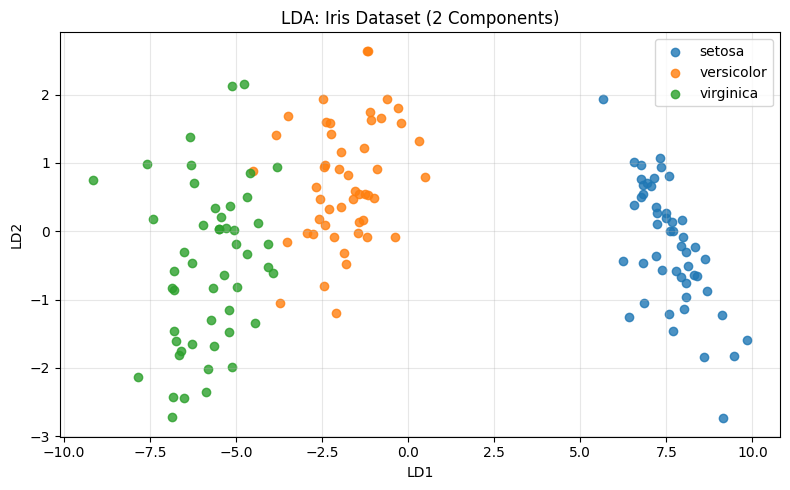

In [6]:
# 5. Plot LDA projection
plt.figure(figsize=(8, 5))
for i, name in enumerate(target_names):
    plt.scatter(
        X_lda[y == i, 0],
        X_lda[y == i, 1],
        label=name,
        alpha=0.8
    )

plt.xlabel("LD1")
plt.ylabel("LD2")
plt.title("LDA: Iris Dataset (2 Components)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

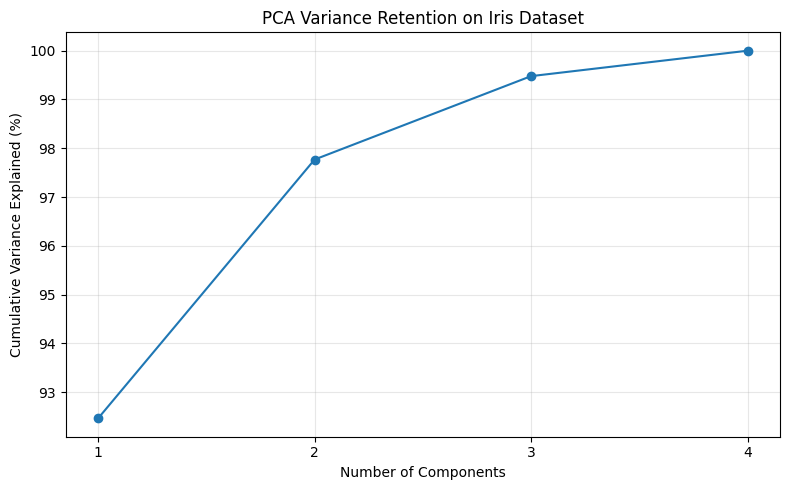

In [7]:
# 6. Compare cumulative PCA variance
components = np.arange(1, 5)
pca_all = PCA(n_components=4)
pca_all.fit(X)

cumulative_variance = np.cumsum(
    pca_all.explained_variance_ratio_
)

plt.figure(figsize=(8, 5))
plt.plot(
    components,
    cumulative_variance * 100,
    marker="o"
)
plt.xticks(components)
plt.xlabel("Number of Components")
plt.ylabel("Cumulative Variance Explained (%)")
plt.title("PCA Variance Retention on Iris Dataset")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


LDA is a **supervised dimensionality-reduction technique**, whereas PCA is **unsupervised**. LDA uses the known flower species labels to find directions that separate classes. For the three Iris species, LDA can produce at most \(C-1=3-1=2\) discriminant components.

Therefore, you can compute a two-component LDA representation, but a **three-component LDA representation is not possible** for the standard Iris dataset. To compare 2 versus 3 components, we can use PCA for the three-component representation or compare LDA with PCA directly.